# 08 · Trained models, including the paper's

The earlier notebooks used a single trained model, Omikuji on TF-IDF. Kähler et al. (arXiv 2607.14882) lead with
XR-Transformer, so this compares the two, adds models built on BGE-M3 embeddings, and saves each model's ranked labels
for the combined method in notebook 10.

| Model | Reads | Runs on |
|---|---|---|
| Omikuji | word counts (TF-IDF), first 500 words | this machine |
| XR-Transformer | BERT-family encoder plus TF-IDF, first 30,000 characters, as in the paper | Hugging Face Jobs, A10G GPU |
| Embedding classifier | BGE-M3 embedding of the first 500 words, one logistic output per label | this machine |
| Similar documents | labels of the nearest training documents, by the same embedding | this machine |
| Label search | nearest label names, by the same embedding; needs no training labels | this machine |

**Fairness.** Each model gets the same choices on the development split: at most so many labels per item, and a minimum
score. Scoring is on the same 600 laws and 1,500 excerpts as the other notebooks, and then the full test splits for
models that need no paid calls.

**What differs from the paper.** The encoder choices are ours, because the paper does not name them; see
`scripts/hf_jobs/train_xr_transformer.py`. Its data is German library records, and ours is not.


In [1]:
import pandas as pd
import torch

from tiered_taxonomy import experiment as ex
from tiered_taxonomy import figures as fg
from tiered_taxonomy import runs
from tiered_taxonomy import signals as sg
from tiered_taxonomy.config import FIGURES, data_root, load_config
from tiered_taxonomy.metrics import micro_f1, paired_difference

root = data_root()
config = load_config()
trained = config["trained"]
limits, thresholds = trained["cut_limits"], trained["cut_thresholds"]
seed = config["seed"]
words = config["text"]["input_words"]
samples = config["samples"]
device = "mps" if torch.backends.mps.is_available() else "cuda" if torch.cuda.is_available() else "cpu"
SOURCES = ("omikuji", "xr_transformer", "embedding_classifier", "knn", "label_search")
results = {"device": device}

/Users/matthewharris/git/nvidia-autoontology-demo/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
def sample_for(data):
    if data.name == ex.EURLEX:
        settings = samples["eurlex"]
        return ex.sample_eurlex(
            data,
            settings["normal_documents"],
            settings["long_documents"],
            settings["long_threshold_words"],
            seed,
        )
    return ex.sample_humset(data, samples["humset"]["per_language"], seed)


def collect(data):
    bench = runs.make_bench(data, root, config)
    details = sg.collect_signals(data, root, trained, seed, words, device, bench.index)
    sg.xr_signals(data, root)
    return details, ex.pilot_subset(data.dev, trained["tuning_items"], seed)


def score_all(data, tuning, details):
    sample = sample_for(data)
    gold = ex.gold_exact(sample)
    gold_full = ex.gold_exact(data.test)
    rows, chosen, predicted = {}, {}, {}
    for source in SOURCES:
        dev = sg.load_signal(root, data.name, source, "dev")
        test = sg.load_signal(root, data.name, source, "test")
        cut, dev_f1 = sg.tuning_cut(tuning, dev, limits, thresholds)
        labels = [cut.apply(test[item.id]) for item in sample]
        ex.save_predictions(root, data.name, source, [item.id for item in sample], labels)
        predicted[source] = labels
        rows[source] = {
            "limit": cut.limit,
            "threshold": cut.threshold,
            "dev_f1": round(dev_f1, 4),
            "scores": ex.evaluate(data, sample, labels),
            "full_test_f1": round(micro_f1(gold_full, [cut.apply(test[item.id]) for item in data.test]), 4),
        }
        chosen[source] = {"limit": cut.limit, "threshold": cut.threshold}
    best = max(SOURCES, key=lambda source: rows[source]["dev_f1"])
    differences = {
        f"{best} minus {other}": [
            round(value, 4) for value in paired_difference(micro_f1, gold, predicted[best], predicted[other])
        ]
        for other in SOURCES
        if other != best
    }
    return {
        "details": details,
        "items": len(sample),
        "methods": rows,
        "best_on_dev": best,
        "differences": differences,
    }


def table(result):
    rows = []
    for name, entry in result["methods"].items():
        row = {
            "method": name,
            "limit": entry["limit"],
            "threshold": entry["threshold"],
            "exact F1": round(entry["scores"]["exact"]["f1"], 3),
            "full test F1": entry["full_test_f1"],
        }
        row.update(
            {f"tier {tier} F1": round(value["f1"], 3) for tier, value in entry["scores"]["tiers"].items()}
        )
        row.update({f"{band} recall": value["recall"] for band, value in entry["scores"]["rarity"].items()})
        rows.append(row)
    return pd.DataFrame(rows)

## MultiEURLEX

In [3]:
data = ex.load_eurlex(root)
details, tuning = collect(data)
results[ex.EURLEX] = score_all(data, tuning, details)
print({key: results[ex.EURLEX][key] for key in ("best_on_dev", "differences")})
table(results[ex.EURLEX])

{'best_on_dev': 'xr_transformer', 'differences': {'xr_transformer minus omikuji': [0.0178, 0.0071, 0.0288], 'xr_transformer minus embedding_classifier': [0.0212, 0.01, 0.0322], 'xr_transformer minus knn': [0.0335, 0.02, 0.0479], 'xr_transformer minus label_search': [0.3317, 0.3133, 0.3486]}}


,method,limit,threshold,exact F1,full test F1,tier 1 F1,tier 2 F1,tier 3 F1,common recall,rare recall,unseen recall
0,omikuji,15,0.10,0.427,0.4749,0.667,0.618,0.608,0.3817,0.0000,0.000
1,xr_transformer,10,0.10,0.445,0.4859,0.718,0.659,0.648,0.4083,0.0000,0.000
2,embedding_classifier,8,0.25,0.424,0.4553,0.694,0.633,0.621,0.3942,0.0000,0.000
3,knn,15,0.40,0.411,0.4373,0.697,0.621,0.580,0.3809,0.0699,0.000
4,label_search,8,0.00,0.113,0.1337,0.476,0.320,0.249,0.1270,0.0753,0.175


## HumSet

In [4]:
data = ex.load_humset(root)
details, tuning = collect(data)
results[ex.HUMSET] = score_all(data, tuning, details)
print({key: results[ex.HUMSET][key] for key in ("best_on_dev", "differences")})
print("items sharing an id with another:", len(data.test) - len({item.id for item in data.test}))
table(results[ex.HUMSET])

{'best_on_dev': 'xr_transformer', 'differences': {'xr_transformer minus omikuji': [0.063, 0.0511, 0.0738], 'xr_transformer minus embedding_classifier': [0.0694, 0.0552, 0.0835], 'xr_transformer minus knn': [0.052, 0.0385, 0.0657], 'xr_transformer minus label_search': [0.5323, 0.5175, 0.5469]}}
items sharing an id with another: 5


,method,limit,threshold,exact F1,full test F1,tier 1 F1,tier 2 F1,common recall,rare recall
0,omikuji,10,0.20,0.579,0.5931,0.618,0.492,0.5763,0.3387
1,xr_transformer,10,0.25,0.642,0.6521,0.686,0.562,0.6366,0.4194
2,embedding_classifier,6,0.30,0.573,0.5851,0.611,0.495,0.5852,0.3871
3,knn,10,0.30,0.590,0.5865,0.635,0.516,0.6207,0.3226
4,label_search,10,0.35,0.110,0.1098,0.231,0.072,0.2527,0.5484


## The chart

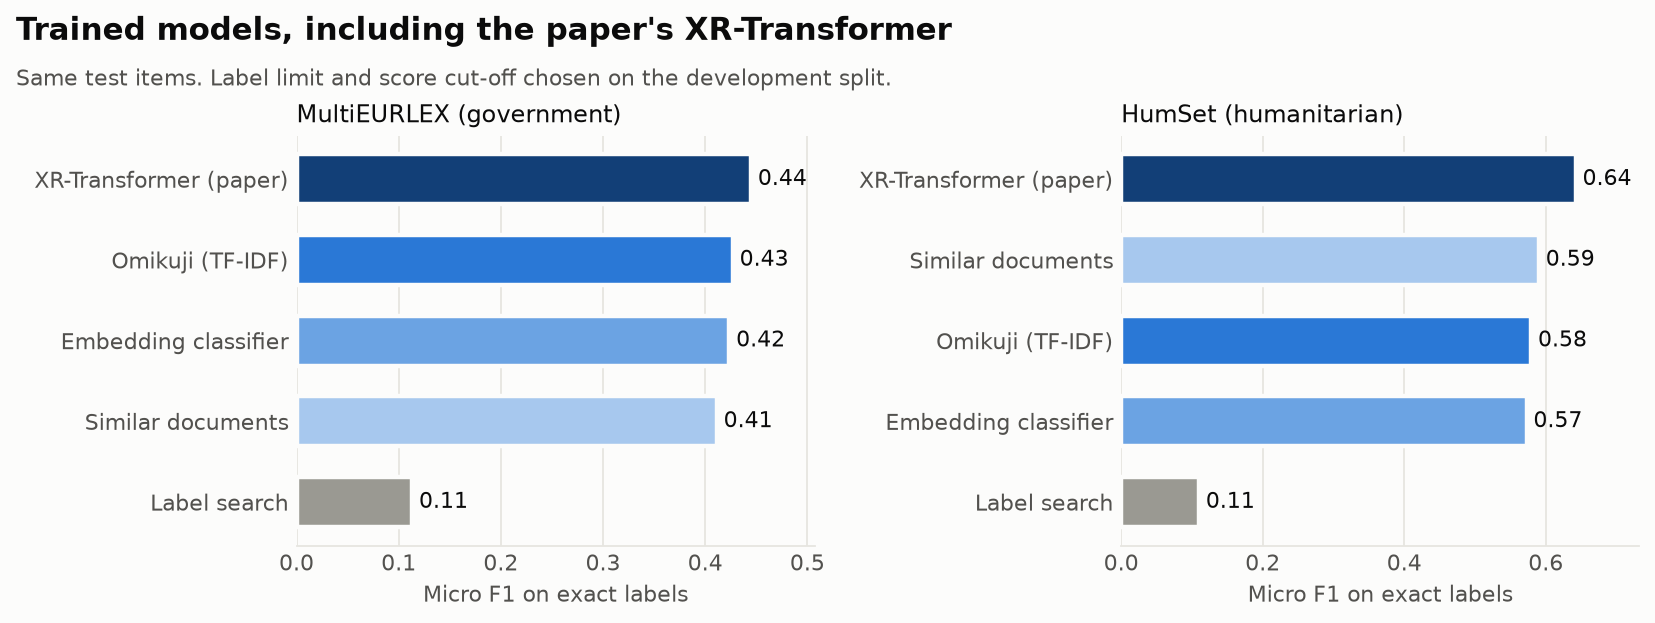

In [5]:
from IPython.display import Image

NAMES = {ex.EURLEX: "MultiEURLEX (government)", ex.HUMSET: "HumSet (humanitarian)"}
panels = {
    NAMES[name]: {
        source: entry["scores"]["exact"]["f1"] for source, entry in results[name]["methods"].items()
    }
    for name in NAMES
}
path = fg.method_bars(
    panels,
    "Micro F1 on exact labels",
    "Trained models, including the paper's XR-Transformer",
    "Same test items. Label limit and score cut-off chosen on the development split.",
    FIGURES / "08_trained_models.png",
)
ex.save_results("08_trained_models", results)
Image(str(path), width=900)